In [3]:
import sqlite3
import pandas as pd

# 1. Load CSV files
accounts = pd.read_csv('accounts.csv')
products = pd.read_csv('products.csv')
pipeline = pd.read_csv('sales_pipeline.csv')
teams = pd.read_csv('sales_teams.csv')

# 2. Connect to an internal SQLite database
conn = sqlite3.connect('sales.db')

# 3. Save DataFrames as SQL tables
accounts.to_sql('accounts', conn, if_exists='replace', index=False)
products.to_sql('products', conn, if_exists='replace', index=False)
pipeline.to_sql('sales_pipeline', conn, if_exists='replace', index=False)
teams.to_sql('sales_teams', conn, if_exists='replace', index=False)

print("Tables loaded into SQL successfully!")

Tables loaded into SQL successfully!


In [4]:
query_1 = """
SELECT 
    product,
    COUNT(opportunity_id) AS total_deals,
    SUM(CASE WHEN deal_stage = 'Won' THEN 1 ELSE 0 END) AS won_deals,
    SUM(CASE WHEN deal_stage = 'Lost' THEN 1 ELSE 0 END) AS lost_deals,
    ROUND(SUM(close_value), 2) AS total_revenue
FROM sales_pipeline
GROUP BY product
ORDER BY total_revenue DESC;
"""

df_products = pd.read_sql_query(query_1, conn)
df_products

,product,total_deals,won_deals,lost_deals,total_revenue
0,GTXPro,1480,729,418,3510578.0
1,GTX Plus Pro,968,479,266,2629651.0
2,MG Advanced,1412,654,430,2216387.0
3,GTX Plus Basic,1383,653,398,705275.0
4,GTX Basic,1866,915,521,499263.0
5,GTK 500,40,15,10,400612.0
6,MG Special,1651,793,430,43768.0


In [5]:
query_2 = """
SELECT 
    sales_agent,
    COUNT(opportunity_id) AS deals_handled,
    SUM(CASE WHEN deal_stage = 'Won' THEN 1 ELSE 0 END) AS deals_won,
    ROUND(SUM(close_value), 2) AS total_sales,
    DENSE_RANK() OVER (ORDER BY SUM(close_value) DESC) AS rank
FROM sales_pipeline
GROUP BY sales_agent
ORDER BY rank
LIMIT 10;
"""

df_reps = pd.read_sql_query(query_2, conn)
df_reps

,sales_agent,deals_handled,deals_won,total_sales,rank
0,Darcel Schlecht,747,349,1153214.0,1
1,Vicki Laflamme,451,221,478396.0,2
2,Kary Hendrixson,438,209,454298.0,3
3,Cassey Cress,346,163,450489.0,4
4,Donn Cantrell,275,158,445860.0,5
5,Reed Clapper,237,155,438336.0,6
6,Zane Levy,349,161,430068.0,7
7,Corliss Cosme,310,150,421036.0,8
8,James Ascencio,267,135,413533.0,9
9,Daniell Hammack,259,114,364229.0,10


C:\Users\vansh\AppData\Local\Temp\ipykernel_28184\1761057492.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_reps, x='total_sales', y='sales_agent', palette='Blues_r')


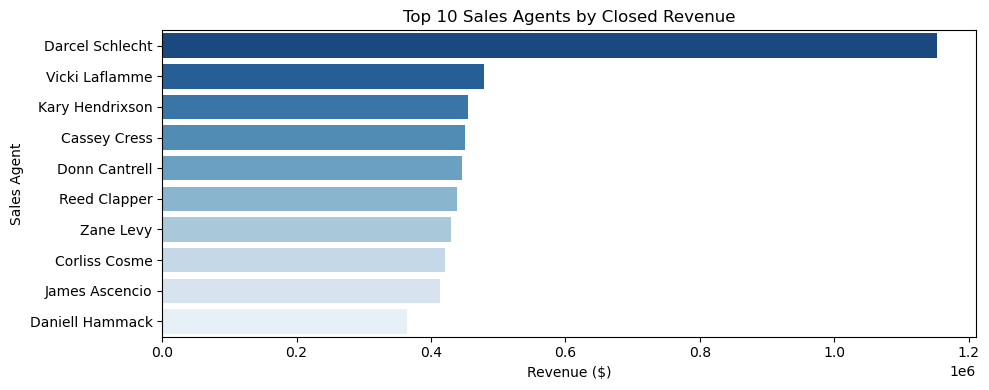

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))

# Horizontal bar chart of top agents
sns.barplot(data=df_reps, x='total_sales', y='sales_agent', palette='Blues_r')
plt.title('Top 10 Sales Agents by Closed Revenue')
plt.xlabel('Revenue ($)')
plt.ylabel('Sales Agent')

plt.tight_layout()
plt.savefig('sales_agent_rankings.png')
plt.show()